<a href="https://colab.research.google.com/github/raayirthrane/replica-of-a-research-paper-on-predicting-mixing-enthalpy-of-liquids-to-amend-CALPHAD-database/blob/main/Replica_redlich.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import torch.nn as nn

class CALPHAD_MLP(nn.Module):
    def __init__(self, input_dim=181):
        super(CALPHAD_MLP, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 352), nn.ReLU(),
            nn.Linear(352, 288),       nn.ReLU(),
            nn.Linear(288, 320),       nn.ReLU(),
            nn.Linear(320, 256),       nn.ReLU(),
            nn.Linear(256, 480),       nn.ReLU(),
            nn.Linear(480, 416),       nn.ReLU(),
            nn.Linear(416, 32),        nn.ReLU(),
            nn.Linear(32, 480),        nn.ReLU(),
            nn.Linear(480, 352),       nn.ReLU(),
            nn.Linear(352, 64),        nn.ReLU(),
            nn.Linear(64, 32),         nn.ReLU(),
            nn.Linear(32, 1)           # Output: predicted H_mix
        )

    def forward(self, x):
        return self.net(x)

model = CALPHAD_MLP(input_dim=181)
print(model)

CALPHAD_MLP(
  (net): Sequential(
    (0): Linear(in_features=181, out_features=352, bias=True)
    (1): ReLU()
    (2): Linear(in_features=352, out_features=288, bias=True)
    (3): ReLU()
    (4): Linear(in_features=288, out_features=320, bias=True)
    (5): ReLU()
    (6): Linear(in_features=320, out_features=256, bias=True)
    (7): ReLU()
    (8): Linear(in_features=256, out_features=480, bias=True)
    (9): ReLU()
    (10): Linear(in_features=480, out_features=416, bias=True)
    (11): ReLU()
    (12): Linear(in_features=416, out_features=32, bias=True)
    (13): ReLU()
    (14): Linear(in_features=32, out_features=480, bias=True)
    (15): ReLU()
    (16): Linear(in_features=480, out_features=352, bias=True)
    (17): ReLU()
    (18): Linear(in_features=352, out_features=64, bias=True)
    (19): ReLU()
    (20): Linear(in_features=64, out_features=32, bias=True)
    (21): ReLU()
    (22): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [ ]:
import numpy as np
import pandas as pd

# Hardcoded binary parameters from mc_fe database
binary_parameters = {
    ("Fe", "Ni"): {"L0": (-9800, -3.2), "L1": (2100, 0.8), "L2": (0, 0)},
    ("Fe", "Cr"): {"L0": (-2130, 1.25), "L1": (-1420, -0.45), "L2": (0, 0)},
    ("Fe", "Al"): {"L0": (-89200, 18.5), "L1": (24500, -4.2), "L2": (-8100, 0)},
    ("Ni", "Cr"): {"L0": (-11200, 2.1), "L1": (3400, 0), "L2": (0, 0)},
    ("Fe", "Mn"): {"L0": (1200, -0.5), "L1": (0, 0), "L2": (0, 0)},
    ("Fe", "Cu"): {"L0": (32800, -9.1), "L1": (-4200, 0), "L2": (0, 0)},
    ("Ni", "Al"): {"L0": (-154000, 31.0), "L1": (38500, -7.5), "L2": (-12000, 0)},
}

def compute_H_mix(elem_A, elem_B, x_A, T):
    x_B = 1.0 - x_A
    pair = (elem_A, elem_B) if (elem_A, elem_B) in binary_parameters else (elem_B, elem_A)
    params = binary_parameters[pair]

    L0 = params['L0'][0] + params['L0'][1] * T
    L1 = params['L1'][0] + params['L1'][1] * T
    L2 = params['L2'][0] + params['L2'][1] * T

    H_excess_J = x_A * x_B * (L0 + L1 * (x_A - x_B) + L2 * ((x_A - x_B)**2))
    return H_excess_J / 1000.0  # Output in kJ/mol

# Generate composition and temperature grid
dataset_rows = []
temperatures = [1600, 1800, 2000]  # K
x_grid = np.linspace(0.01, 0.99, 99)

for (A, B) in binary_parameters.keys():
    for T in temperatures:
        for x_A in x_grid:
            dataset_rows.append({
                "Elem_A": A,
                "Elem_B": B,
                "x_A": x_A,
                "x_B": 1.0 - x_A,
                "T": T,
                "delta_H_mix": compute_H_mix(A, B, x_A, T)
            })

df = pd.DataFrame(dataset_rows)
print(df)
y_data = df["delta_H_mix"].values  # Target array for training


     Elem_A Elem_B   x_A   x_B     T  delta_H_mix
0        Fe     Ni  0.01  0.99  1600    -0.180501
1        Fe     Ni  0.02  0.98  1600    -0.356030
2        Fe     Ni  0.03  0.97  1600    -0.526629
3        Fe     Ni  0.04  0.96  1600    -0.692337
4        Fe     Ni  0.05  0.95  1600    -0.853195
...     ...    ...   ...   ...   ...          ...
2074     Ni     Al  0.95  0.05  2000    -3.827075
2075     Ni     Al  0.96  0.04  2000    -3.092613
2076     Ni     Al  0.97  0.03  2000    -2.342934
2077     Ni     Al  0.98  0.02  2000    -1.577784
2078     Ni     Al  0.99  0.01  2000    -0.796899

[2079 rows x 6 columns]


In [ ]:
import numpy as np
import pandas as pd

# Hardcoded elemental physical parameters
ELEMENT_DB = {
    'Fe': {'Z': 26, 'mass': 55.845, 'radius': 126, 'X': 1.83, 'valence': 8, 'melt_K': 1811, 'heat_fus': 13.81},
    'Ni': {'Z': 28, 'mass': 58.693, 'radius': 124, 'X': 1.91, 'valence': 10, 'melt_K': 1728, 'heat_fus': 17.48},
    'Cr': {'Z': 24, 'mass': 51.996, 'radius': 128, 'X': 1.66, 'valence': 6, 'melt_K': 2180, 'heat_fus': 21.00},
    'Al': {'Z': 13, 'mass': 26.982, 'radius': 143, 'X': 1.61, 'valence': 3, 'melt_K': 933.4, 'heat_fus': 10.71},
    'Mn': {'Z': 25, 'mass': 54.938, 'radius': 127, 'X': 1.55, 'valence': 7, 'melt_K': 1519, 'heat_fus': 12.91},
    'Cu': {'Z': 29, 'mass': 63.546, 'radius': 128, 'X': 1.90, 'valence': 11, 'melt_K': 1357.7, 'heat_fus': 13.26},
    'V':  {'Z': 23, 'mass': 50.941, 'radius': 134, 'X': 1.63, 'valence': 5, 'melt_K': 2183, 'heat_fus': 21.50},
}

rows = []
for idx, row in df.iterrows():
    eA = ELEMENT_DB[row['Elem_A']]
    eB = ELEMENT_DB[row['Elem_B']]
    xA, xB, T = row['x_A'], row['x_B'], row['T']

    # Feature vector: [State, A_props, B_props, Weighted_props, Differences]
    feat = [
        xA, xB, T,
        eA['Z'], eA['radius'], eA['X'], eA['valence'], eA['melt_K'], eA['heat_fus'],
        eB['Z'], eB['radius'], eB['X'], eB['valence'], eB['melt_K'], eB['heat_fus'],
        xA*eA['radius'] + xB*eB['radius'],  # Weighted Radius
        xA*eA['X'] + xB*eB['X'],            # Weighted Electronegativity
        abs(eA['radius'] - eB['radius']),   # Radius difference
        abs(eA['X'] - eB['X'])               # Electronegativity difference
    ]
    rows.append(feat)
X_data = np.array(rows, dtype=np.float32)
column_names = [
    'x_A', 'x_B', 'T',
    'Z_A', 'radius_A', 'X_A', 'valence_A', 'melt_K_A', 'heat_fus_A',
    'Z_B', 'radius_B', 'X_B', 'valence_B', 'melt_K_B', 'heat_fus_B',
    'Weighted_Radius', 'Weighted_Electronegativity',
    'Radius_Diff', 'Electronegativity_Diff'
]

F_data = pd.DataFrame(X_data, columns=column_names)

print(F_data)
print("Manual feature matrix shape:", X_data.shape)

       x_A   x_B       T   Z_A  radius_A   X_A  valence_A  melt_K_A  \
0     0.01  0.99  1600.0  26.0     126.0  1.83        8.0    1811.0   
1     0.02  0.98  1600.0  26.0     126.0  1.83        8.0    1811.0   
2     0.03  0.97  1600.0  26.0     126.0  1.83        8.0    1811.0   
3     0.04  0.96  1600.0  26.0     126.0  1.83        8.0    1811.0   
4     0.05  0.95  1600.0  26.0     126.0  1.83        8.0    1811.0   
...    ...   ...     ...   ...       ...   ...        ...       ...   
2074  0.95  0.05  2000.0  28.0     124.0  1.91       10.0    1728.0   
2075  0.96  0.04  2000.0  28.0     124.0  1.91       10.0    1728.0   
2076  0.97  0.03  2000.0  28.0     124.0  1.91       10.0    1728.0   
2077  0.98  0.02  2000.0  28.0     124.0  1.91       10.0    1728.0   
2078  0.99  0.01  2000.0  28.0     124.0  1.91       10.0    1728.0   

      heat_fus_A   Z_B  radius_B   X_B  valence_B     melt_K_B  heat_fus_B  \
0          13.81  28.0     124.0  1.91       10.0  1728.000000       

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# Define the MLP model structure
class CALPHAD_MLP(nn.Module):
    def __init__(self, input_dim=19):
        super(CALPHAD_MLP, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 352), nn.ReLU(),
            nn.Linear(352, 288),       nn.ReLU(),
            nn.Linear(288, 320),       nn.ReLU(),
            nn.Linear(320, 256),       nn.ReLU(),
            nn.Linear(256, 480),       nn.ReLU(),
            nn.Linear(480, 416),       nn.ReLU(),
            nn.Linear(416, 32),        nn.ReLU(),
            nn.Linear(32, 480),        nn.ReLU(),
            nn.Linear(480, 352),       nn.ReLU(),
            nn.Linear(352, 64),        nn.ReLU(),
            nn.Linear(64, 32),         nn.ReLU(),
            nn.Linear(32, 1)           # Output: predicted H_mix
        )

    def forward(self, x):
        return self.net(x)

class CALPHADDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32).unsqueeze(1)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# Initialize dataset & dataloader
dataset = CALPHADDataset(X_data, y_data)
train_loader = DataLoader(dataset, batch_size=64, shuffle=True)

# Train the model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
input_dim = X_data.shape[1]  # Automatically adapts to total features
model = CALPHAD_MLP(input_dim=input_dim).to(device)

criterion = torch.nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

for epoch in range(50):
    model.train()
    for batch_X, batch_y in train_loader:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)
        optimizer.zero_grad()
        loss = criterion(model(batch_X), batch_y)
        loss.backward()
        optimizer.step()
for epoch in range(50):
    model.train()
    epoch_loss = 0 # Track loss for the entire epoch

    for batch_X, batch_y in train_loader:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)
        optimizer.zero_grad()
        loss = criterion(model(batch_X), batch_y)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item() # Add batch loss

    # Print the average loss every 10 epochs
    if (epoch + 1) % 10 == 0:
        avg_loss = epoch_loss / len(train_loader)
        print(f"Epoch {epoch+1}/50, Average Loss: {avg_loss:.4f}")
# Set model to evaluation mode
model.eval()

# Turn off gradient calculation for inference (saves memory/time)
with torch.no_grad():
    # Convert all your raw features into a tensor and move to device
    X_tensor = torch.tensor(X_data, dtype=torch.float32).to(device)

    # Get the predictions
    predictions = model(X_tensor)

    # Move predictions back to CPU and convert to a numpy array for easy viewing
    final_results = predictions.cpu().numpy()

    print("\n--- Final Model Predictions ---")
    print(final_results)
    print(final_results.shape)

Epoch 10/50, Average Loss: 15.6305
Epoch 20/50, Average Loss: 13.2970
Epoch 30/50, Average Loss: 11.6496
Epoch 40/50, Average Loss: 10.9241
Epoch 50/50, Average Loss: 12.7092

--- Final Model Predictions ---
[[ -2.7359595]
 [ -2.7360916]
 [ -2.7362227]
 ...
 [-14.456368 ]
 [-14.427702 ]
 [-14.3990345]]
(2079, 1)


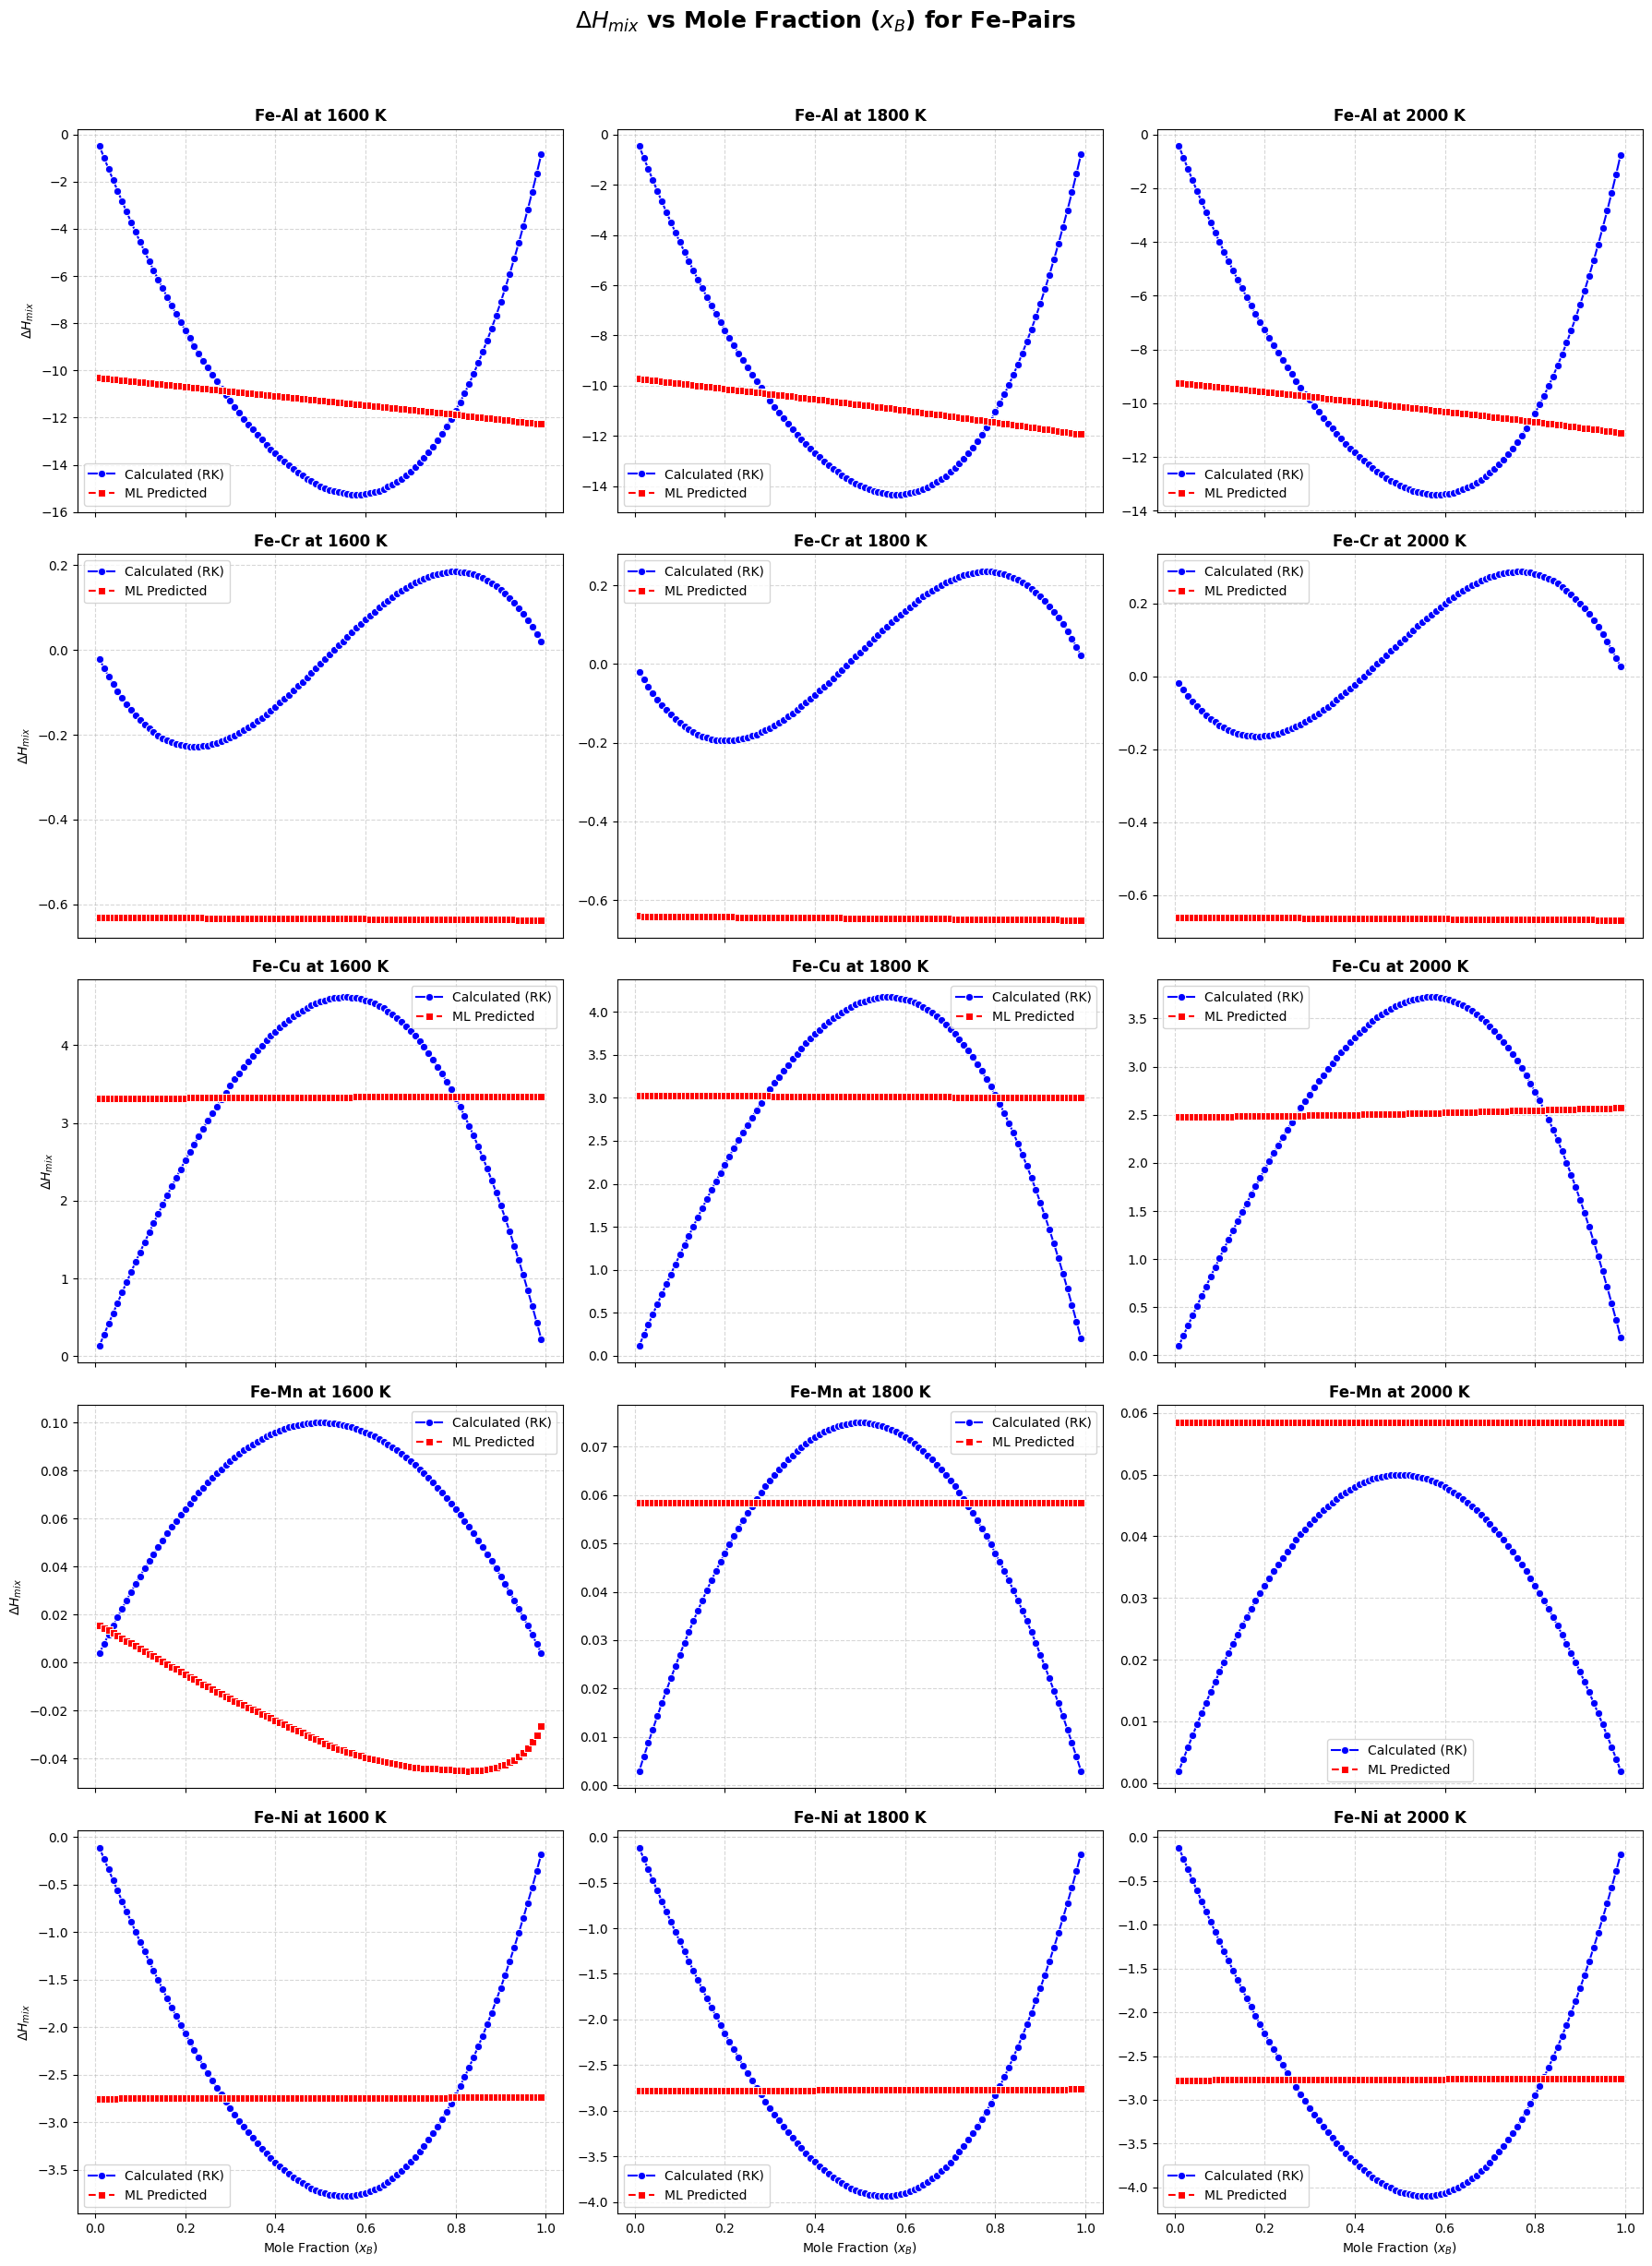

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Attach calculated and predicted data back to the main DataFrame
df['Hmix_calc'] = y_data
df['Hmix_pred'] = final_results

# 2. Filter for pairs containing Iron (Fe)
fe_df = df[(df['Elem_A'] == 'Fe') | (df['Elem_B'] == 'Fe')].copy()

# 3. Create a clean Pair label
fe_df['Pair'] = fe_df.apply(lambda row: f"{row['Elem_A']}-{row['Elem_B']}", axis=1)

# 4. Sort by mole fraction so lines draw sequentially
fe_df = fe_df.sort_values(by=['Pair', 'T', 'x_B'])

# 5. Extract unique temperatures and unique pairs
temperatures = sorted(fe_df['T'].unique())
pairs = sorted(fe_df['Pair'].unique())

n_pairs = len(pairs)
n_temps = len(temperatures)

# 6. Create a grid (Rows: Pairs | Columns: Temperatures)
fig, axes = plt.subplots(n_pairs, n_temps, figsize=(18, 5 * n_pairs), sharex=True)
fig.suptitle(r'$\Delta H_{mix}$ vs Mole Fraction ($x_B$) for Fe-Pairs', fontsize=18, fontweight='bold', y=0.98)

# Handle cases where there is only one pair or one temperature (axes array dimension adjustment)
if n_pairs == 1 and n_temps == 1:
    axes = np.array([[axes]])
elif n_pairs == 1:
    axes = np.array([axes])
elif n_temps == 1:
    axes = np.array([[ax] for ax in axes])

# 7. Iterate through each pair and temperature to populate the grid
for row_idx, pair in enumerate(pairs):
    for col_idx, temp in enumerate(temperatures):
        ax = axes[row_idx, col_idx]

        # Isolate data for the current pair and temperature
        subset = fe_df[(fe_df['Pair'] == pair) & (fe_df['T'] == temp)]

        if subset.empty:
            ax.set_visible(False) # Hide empty plots if a pair doesn't have data at a specific temp
            continue

        # Plot Calculated Data
        sns.lineplot(
            data=subset,
            x='x_B',
            y='Hmix_calc',
            marker='o',
            color='blue',
            label='Calculated (RK)',
            ax=ax
        )

        # Plot Predicted Data
        sns.lineplot(
            data=subset,
            x='x_B',
            y='Hmix_pred',
            marker='s',
            color='red',
            linestyle='--',
            label='ML Predicted',
            ax=ax
        )

        # Formatting
        ax.set_title(f'{pair} at {temp} K', fontweight='bold')
        ax.grid(True, linestyle='--', alpha=0.5)

        # Set x-labels only on the bottom row
        if row_idx == n_pairs - 1:
            ax.set_xlabel(r'Mole Fraction ($x_B$)')
        else:
            ax.set_xlabel('')

        # Set y-labels only on the first column
        if col_idx == 0:
            ax.set_ylabel(r'$\Delta H_{mix}$')
        else:
            ax.set_ylabel('')

# Adjust layout to prevent overlap
plt.tight_layout(rect=[0, 0, 1, 0.96]) # Leave room for the main suptitle
plt.show()

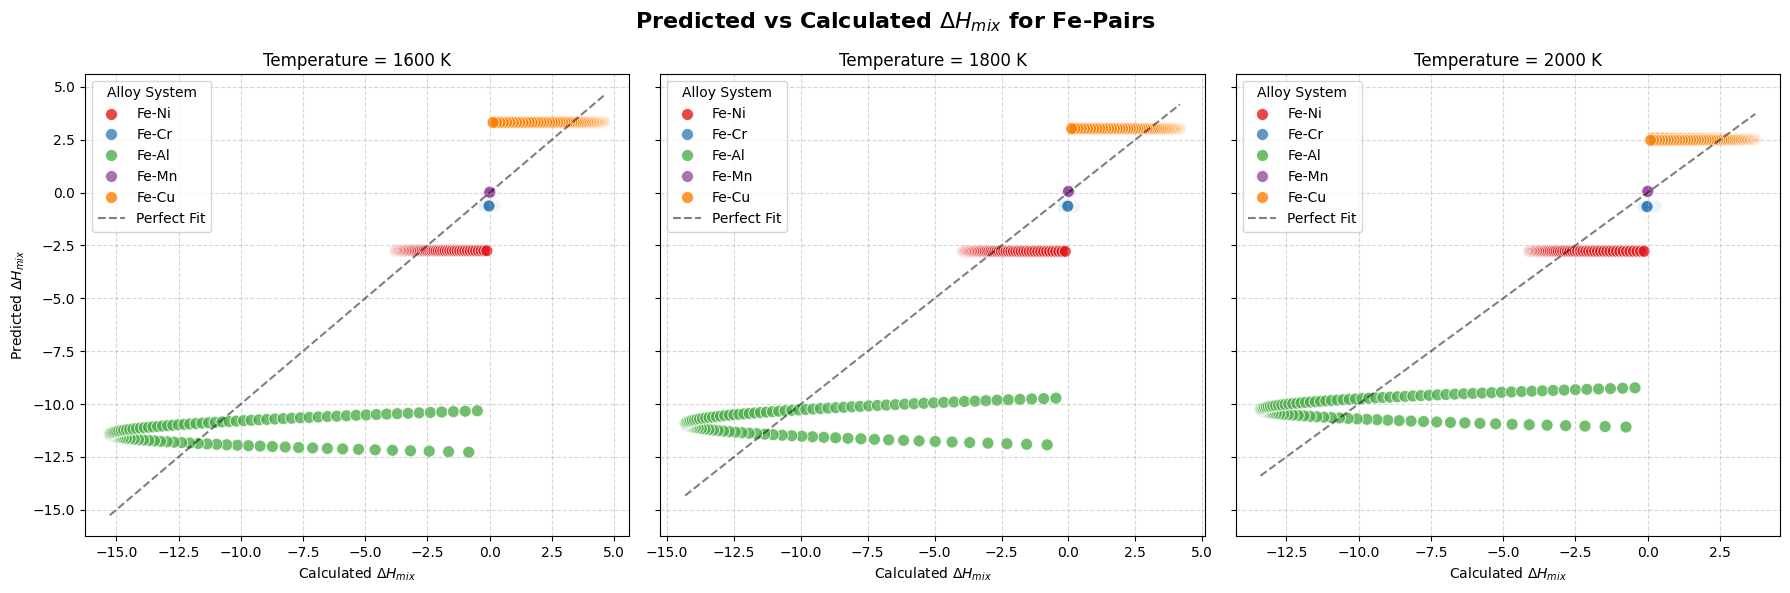

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Append the actual and predicted values back into your main DataFrame
df['Hmix_calc'] = y_data
df['Hmix_pred'] = final_results

# 2. Filter the DataFrame to only include rows where Element A or Element B is Iron (Fe)
fe_df = df[(df['Elem_A'] == 'Fe') | (df['Elem_B'] == 'Fe')].copy()

# 3. Create a "Pair" column for the legend (e.g., "Fe-Ni", "Fe-Cr")
fe_df['Pair'] = fe_df.apply(lambda row: f"{row['Elem_A']}-{row['Elem_B']}", axis=1)

# 4. Get the three unique temperatures from the dataset
temperatures = sorted(fe_df['T'].unique())

# 5. Set up a 1x3 plotting grid
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
fig.suptitle(r'Predicted vs Calculated $\Delta H_{mix}$ for Fe-Pairs', fontsize=16, fontweight='bold')

for idx, temp in enumerate(temperatures):
    ax = axes[idx]

    # Isolate the data for the current temperature
    subset = fe_df[fe_df['T'] == temp]

    # Plot Calculated (x-axis) vs Predicted (y-axis), colored by the specific alloy pair
    sns.scatterplot(
        data=subset,
        x='Hmix_calc',
        y='Hmix_pred',
        hue='Pair',
        palette='Set1', # Gives distinct colors to each pair
        s=75,           # Marker size
        alpha=0.8,
        ax=ax
    )

    # Add a y = x parity line to indicate perfect predictions
    if not subset.empty:
        min_val = min(subset['Hmix_calc'].min(), subset['Hmix_pred'].min())
        max_val = max(subset['Hmix_calc'].max(), subset['Hmix_pred'].max())
        ax.plot([min_val, max_val], [min_val, max_val], 'k--', alpha=0.5, label='Perfect Fit')

    # Format labels and titles
    ax.set_title(f'Temperature = {temp} K')
    ax.set_xlabel(r'Calculated $\Delta H_{mix}$')

    # Only label the y-axis on the far left plot to keep it clean
    if idx == 0:
        ax.set_ylabel(r'Predicted $\Delta H_{mix}$')
    else:
        ax.set_ylabel('')

    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(title='Alloy System', loc='best')

plt.tight_layout()
plt.show()

CALPHAD Redlich-Kister Parameters for Fe-Cr at 1800.0 K:
  L0 =      -2.26 kJ/mol  (   -2261.3 J/mol)
  L1 =       0.03 kJ/mol  (      34.5 J/mol)
  L2 =      -6.77 kJ/mol  (   -6768.4 J/mol)

CALPHAD .TDB Syntax Lines:
PARAMETER L(LIQUID,FE,CR;0) 298.15 -2261.3; 6000 N !
PARAMETER L(LIQUID,FE,CR;1) 298.15 34.5; 6000 N !
PARAMETER L(LIQUID,FE,CR;2) 298.15 -6768.4; 6000 N !

CALPHAD Redlich-Kister Parameters for Fe-Mn at 1800.0 K:
  L0 =       0.20 kJ/mol  (     204.7 J/mol)
  L1 =       0.00 kJ/mol  (       0.0 J/mol)
  L2 =       0.61 kJ/mol  (     612.7 J/mol)

CALPHAD .TDB Syntax Lines:
PARAMETER L(LIQUID,FE,MN;0) 298.15 204.7; 6000 N !
PARAMETER L(LIQUID,FE,MN;1) 298.15 0.0; 6000 N !
PARAMETER L(LIQUID,FE,MN;2) 298.15 612.7; 6000 N !

CALPHAD Redlich-Kister Parameters for Fe-Al at 1800.0 K:
  L0 =     -37.59 kJ/mol  (  -37589.2 J/mol)
  L1 =       7.81 kJ/mol  (    7810.6 J/mol)
  L2 =    -113.56 kJ/mol  ( -113563.5 J/mol)

CALPHAD .TDB Syntax Lines:
PARAMETER L(LIQUID,FE,AL;0) 298

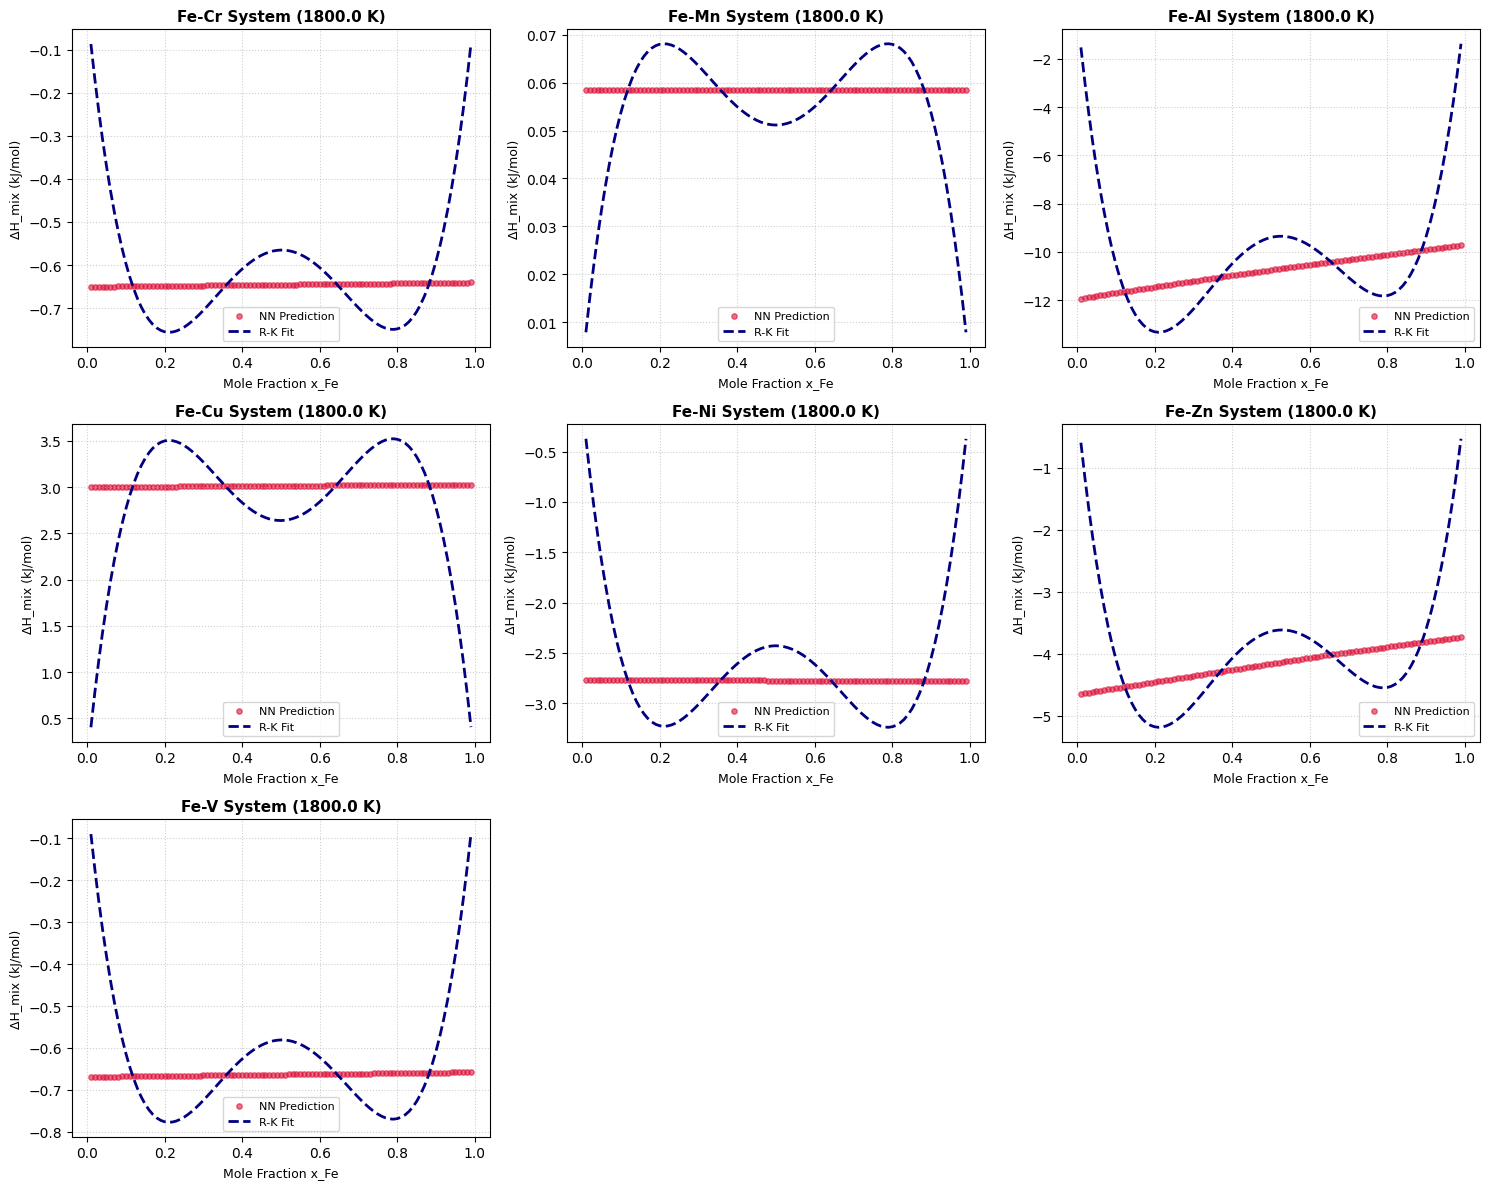

In [ ]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Ensure Zn is present in ELEMENT_DB alongside other elements
ELEMENT_DB['Zn'] = {'Z': 30, 'mass': 65.38, 'radius': 134, 'X': 1.65, 'valence': 2, 'melt_K': 692.68, 'heat_fus': 7.32}

# =====================================================================
# 1. HELPER FUNCTIONS
# =====================================================================
def extract_features_for_system(elem_A, elem_B, x_A_grid, temperature):
    """Constructs feature matrix matching your manual ELEMENT_DB layout."""
    eA = ELEMENT_DB[elem_A]
    eB = ELEMENT_DB[elem_B]

    rows = []
    for xA in x_A_grid:
        xB = 1.0 - xA
        feat = [
            xA, xB, temperature,
            eA['Z'], eA['radius'], eA['X'], eA['valence'], eA['melt_K'], eA['heat_fus'],
            eB['Z'], eB['radius'], eB['X'], eB['valence'], eB['melt_K'], eB['heat_fus'],
            xA * eA['radius'] + xB * eB['radius'],  # Weighted Radius
            xA * eA['X'] + xB * eB['X'],            # Weighted Electronegativity
            abs(eA['radius'] - eB['radius']),      # Radius difference
            abs(eA['X'] - eB['X'])                  # Electronegativity difference
        ]
        rows.append(feat)

    return np.array(rows, dtype=np.float32)

def redlich_kister(x_A, L0, L1, L2):
    """Redlich-Kister excess enthalpy polynomial equation."""
    x_B = 1.0 - x_A
    return x_A * x_B * (L0 + L1 * (x_A - x_B) + L2 * ((x_A - x_B)**2))

# =====================================================================
# 2. BATCH PROCESSING FOR MULTIPLE FE BINARY SYSTEMS
# =====================================================================
test_elem_A = 'Fe'
target_elements = ['Cr', 'Mn', 'Al', 'Cu', 'Ni', 'Zn', 'V']
test_temperature = 1800.0  # Kelvin
x_test_grid = np.linspace(0.01, 0.99, 99)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.eval()

# Set up Matplotlib subplots grid
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(15, 12))
axes = axes.flatten()

fitted_results = []

for idx, test_elem_B in enumerate(target_elements):
    # Extract features and predict using trained Neural Network
    X_test = extract_features_for_system(test_elem_A, test_elem_B, x_test_grid, test_temperature)
    X_test_tensor = torch.tensor(X_test, dtype=torch.float32).to(device)

    with torch.no_grad():
        predicted_H_mix = model(X_test_tensor).cpu().numpy().flatten()

    # Least-squares fit to get L0, L1, L2 (in kJ/mol)
    popt, _ = curve_fit(redlich_kister, x_test_grid, predicted_H_mix)
    L0_fit, L1_fit, L2_fit = popt

    fitted_results.append({
        'System': f"{test_elem_A}-{test_elem_B}",
        'L0_kJ': L0_fit, 'L1_kJ': L1_fit, 'L2_kJ': L2_fit,
        'L0_J': L0_fit * 1000, 'L1_J': L1_fit * 1000, 'L2_J': L2_fit * 1000
    })

    # Output parameters in console
    print("=" * 65)
    print(f"CALPHAD Redlich-Kister Parameters for {test_elem_A}-{test_elem_B} at {test_temperature} K:")
    print("=" * 65)
    print(f"  L0 = {L0_fit:10.2f} kJ/mol  ({L0_fit * 1000:10.1f} J/mol)")
    print(f"  L1 = {L1_fit:10.2f} kJ/mol  ({L1_fit * 1000:10.1f} J/mol)")
    print(f"  L2 = {L2_fit:10.2f} kJ/mol  ({L2_fit * 1000:10.1f} J/mol)")
    print("\nCALPHAD .TDB Syntax Lines:")
    print(f"PARAMETER L(LIQUID,{test_elem_A.upper()},{test_elem_B.upper()};0) 298.15 {L0_fit * 1000:.1f}; 6000 N !")
    print(f"PARAMETER L(LIQUID,{test_elem_A.upper()},{test_elem_B.upper()};1) 298.15 {L1_fit * 1000:.1f}; 6000 N !")
    print(f"PARAMETER L(LIQUID,{test_elem_A.upper()},{test_elem_B.upper()};2) 298.15 {L2_fit * 1000:.1f}; 6000 N !\n")

    # --- PLOTTING ---
    ax = axes[idx]
    H_fit_curve = redlich_kister(x_test_grid, L0_fit, L1_fit, L2_fit)

    ax.scatter(x_test_grid, predicted_H_mix, color='crimson', s=15, alpha=0.6, label='NN Prediction')
    ax.plot(x_test_grid, H_fit_curve, color='navy', linestyle='--', linewidth=2, label='R-K Fit')
    ax.set_title(f'{test_elem_A}-{test_elem_B} System ({test_temperature} K)', fontsize=11, fontweight='bold')
    ax.set_xlabel(f'Mole Fraction x_{test_elem_A}', fontsize=9)
    ax.set_ylabel('ΔH_mix (kJ/mol)', fontsize=9)
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(fontsize=8)

# Hide remaining empty subplots
for i in range(len(target_elements), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import torch
import torch.nn as nn
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Scale Features (X) and Targets (y)
scaler_X = StandardScaler()
X_scaled = scaler_X.fit_transform(X_data)

scaler_y = StandardScaler()
y_scaled = scaler_y.fit_transform(y_data.reshape(-1, 1)).flatten()

# 2. Configure 10-Fold Cross-Validation
kf = KFold(n_splits=10, shuffle=True, random_state=42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Dictionaries to store metrics for stability checks
fold_metrics = {'mae': [], 'rmse': [], 'r2': []}

# Define your model creation as a function so it resets every fold
def create_model():
    # Replace this with your actual neural network architecture
    # Increase layers/neurons if your R2 is stuck around 0.69
    return nn.Sequential(
        nn.Linear(X_scaled.shape[1], 128),
        nn.ReLU(),
        nn.Linear(128, 64),
        nn.ReLU(),
        nn.Linear(64, 1)
    )
print("=" * 65)
print("STARTING 10-FOLD CROSS-VALIDATION")
print("=" * 65)

for fold, (train_idx, val_idx) in enumerate(kf.split(X_scaled)):
    # Split data for this fold
    X_train, X_val = X_scaled[train_idx], X_scaled[val_idx]
    y_train, y_val = y_scaled[train_idx], y_scaled[val_idx]

    # Convert to PyTorch Tensors
    X_train_tensor = torch.tensor(X_train, dtype=torch.float32).to(device)
    y_train_tensor = torch.tensor(y_train, dtype=torch.float32).view(-1, 1).to(device)
    X_val_tensor = torch.tensor(X_val, dtype=torch.float32).to(device)
    y_val_tensor = torch.tensor(y_val, dtype=torch.float32).view(-1, 1).to(device)

    # Re-initialize model, optimizer, and loss for every fold
    model = create_model().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.HuberLoss() # Better for this thermodynamic task than MSE

    # Basic Training Loop (Adjust epochs as needed)
    epochs = 500
    model.train()
    for epoch in range(epochs):
        optimizer.zero_grad()
        predictions = model(X_train_tensor)
        loss = criterion(predictions, y_train_tensor)
        loss.backward()
        optimizer.step()

    # --- EVALUATION ON UNSEEN FOLD DATA ---
    model.eval()
    with torch.no_grad():
        val_preds_scaled = model(X_val_tensor).cpu().numpy()

    # Inverse transform to get back to original kJ/mol scale
    val_preds_kj = scaler_y.inverse_transform(val_preds_scaled).flatten()
    y_val_actual_kj = scaler_y.inverse_transform(y_val.reshape(-1, 1)).flatten()

    # Multiply by 1000 to match the research paper's J/mol units
    val_preds_J = val_preds_kj * 1000
    y_val_actual_J = y_val_actual_kj * 1000

    # Calculate fold metrics
    mae = mean_absolute_error(y_val_actual_J, val_preds_J)
    rmse = np.sqrt(mean_squared_error(y_val_actual_J, val_preds_J))
    r2 = r2_score(y_val_actual_J, val_preds_J)

    fold_metrics['mae'].append(mae)
    fold_metrics['rmse'].append(rmse)
    fold_metrics['r2'].append(r2)

    print(f"Fold {fold+1:02d} | MAE: {mae:6.2f} J/mol | RMSE: {rmse:6.2f} J/mol | R²: {r2:.4f}")
    # --- STABILITY CHECKS & FINAL RESULTS ---
mae_array = np.array(fold_metrics['mae'])
rmse_array = np.array(fold_metrics['rmse'])
r2_array = np.array(fold_metrics['r2'])

print("\n" + "=" * 65)
print("10-FOLD CROSS-VALIDATION RESULTS & STABILITY CHECK")
print("=" * 65)
print(f" Mean Absolute Error (MAE)  : {mae_array.mean():.2f} ± {mae_array.std():.2f} J/mol")
print(f" Root Mean Squared Error    : {rmse_array.mean():.2f} ± {rmse_array.std():.2f} J/mol")
print(f" R-Squared Score (R²)       : {r2_array.mean():.4f} ± {r2_array.std():.4f}")
print("=" * 65)

# Identify the best model (closest to the paper's Fold 7)
best_fold_idx = np.argmin(mae_array)
print(f"Best Model found on Fold {best_fold_idx + 1} with MAE: {mae_array[best_fold_idx]:.2f} J/mol")

STARTING 10-FOLD CROSS-VALIDATION
Fold 01 | MAE:  45.80 J/mol | RMSE:  76.03 J/mol | R²: 0.9999
Fold 02 | MAE:  49.58 J/mol | RMSE:  81.62 J/mol | R²: 0.9999
Fold 03 | MAE:  41.38 J/mol | RMSE:  55.82 J/mol | R²: 0.9999
Fold 04 | MAE:  60.02 J/mol | RMSE: 153.66 J/mol | R²: 0.9994
Fold 05 | MAE:  48.40 J/mol | RMSE:  76.96 J/mol | R²: 0.9999
Fold 06 | MAE:  52.22 J/mol | RMSE:  84.69 J/mol | R²: 0.9998
Fold 07 | MAE:  58.30 J/mol | RMSE:  91.10 J/mol | R²: 0.9998
Fold 08 | MAE:  54.63 J/mol | RMSE: 102.15 J/mol | R²: 0.9998
Fold 09 | MAE:  49.91 J/mol | RMSE:  71.06 J/mol | R²: 0.9999
Fold 10 | MAE:  71.94 J/mol | RMSE: 137.67 J/mol | R²: 0.9996

10-FOLD CROSS-VALIDATION RESULTS & STABILITY CHECK
 Mean Absolute Error (MAE)  : 53.22 ± 8.17 J/mol
 Root Mean Squared Error    : 93.08 ± 28.93 J/mol
 R-Squared Score (R²)       : 0.9998 ± 0.0002
Best Model found on Fold 3 with MAE: 41.38 J/mol


In [ ]:
  print("\n" + "=" * 65)
  print("TRAINING FINAL MODEL ON 100% OF DATA")
  print("=" * 65)

  # 1. Create the final model
  final_model = create_model().to(device)
  optimizer = torch.optim.Adam(final_model.parameters(), lr=0.001)
  criterion = torch.nn.HuberLoss()

  # 2. Use the scaled data from Step 1
  X_all_tensor = torch.tensor(X_scaled, dtype=torch.float32).to(device)
  y_all_tensor = torch.tensor(y_scaled, dtype=torch.float32).view(-1, 1).to(device)

  # 3. Train the final model
  final_model.train()
  for epoch in range(500): # Use the best epoch count found during cross-validation
      optimizer.zero_grad()
      predictions = final_model(X_all_tensor)
      loss = criterion(predictions, y_all_tensor)
      loss.backward()
      optimizer.step()

  print("Final model trained and ready for Redlich-Kister predictions.")
  for idx, test_elem_B in enumerate(target_elements):
    # 1. Extract features for the current binary system
    X_test = extract_features_for_system(test_elem_A, test_elem_B, x_test_grid, test_temperature)

    # 2. SCALE THE INPUTS using the scaler fitted during cross-validation
    X_test_scaled = scaler_X.transform(X_test)
    X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32).to(device)

    # 3. Predict using the FINAL model
    final_model.eval()
    with torch.no_grad():
        predicted_H_mix_scaled = final_model(X_test_tensor).cpu().numpy()

    # 4. INVERSE SCALE THE PREDICTIONS back to original kJ/mol scale
    predicted_H_mix = scaler_y.inverse_transform(predicted_H_mix_scaled).flatten()

    # --- Your original curve fitting and plotting code continues here ---
    # Least-squares fit to get L0, L1, L2 (in kJ/mol)
    popt, _ = curve_fit(redlich_kister, x_test_grid, predicted_H_mix)
    L0_fit, L1_fit, L2_fit = popt

    # ... (the rest of your dictionary appending, print statements, and matplotlib code)


TRAINING FINAL MODEL ON 100% OF DATA
Final model trained and ready for Redlich-Kister predictions.
